# Image Colorization With a Small Autoencoder

Grayscale in, RGB out. Trained on a CIFAR-10 slice — convert each image to grayscale on the fly, the original RGB is the target. The model is a small encoder-decoder CNN, nothing fancy. The point of the notebook is to show *before/after* samples that look like reasonable colorizations on the few classes the model gets to see; I'm not chasing a metric here.

CPU-friendly: 1-2 epochs, 5000-image slice. Don't expect saturated colors — small autoencoders trained on a small slice tend to produce desaturated guesses that lean toward the mean color of each class. That's exactly the behavior I want to show qualitatively.

In [1]:
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

torch.manual_seed(3); np.random.seed(3)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

device: cpu


## Data — CIFAR-10, grayscale→RGB pairs

In [2]:
tf = transforms.ToTensor()
DATA_ROOT = "../../data/cifar10_cache"
try:
    train_full = datasets.CIFAR10(DATA_ROOT, train=True, download=True, transform=tf)
    test_full  = datasets.CIFAR10(DATA_ROOT, train=False, download=True, transform=tf)
    train_ds = Subset(train_full, list(range(5000)))
    test_ds  = Subset(test_full, list(range(200)))
    train_dl = DataLoader(train_ds, batch_size=64, shuffle=True)
    test_dl  = DataLoader(test_ds, batch_size=32, shuffle=False)
    have_data = True
    print("CIFAR-10 ready")
except Exception as e:
    have_data = False
    print("no CIFAR-10 available:", e)

def to_gray(x):
    # x: (B, 3, H, W), output (B, 1, H, W) using standard luma weights
    r, g, b = x[:, 0:1], x[:, 1:2], x[:, 2:3]
    return 0.2989 * r + 0.5870 * g + 0.1140 * b

CIFAR-10 ready


## The autoencoder

Encoder downsamples to 8x8x64, decoder upsamples back to 32x32x3. Tanh output, target re-scaled to [-1, 1] (helps with the otherwise-clipped output).

In [3]:
class ColorAE(nn.Module):
    def __init__(self):
        super().__init__()
        # encoder
        self.enc = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(inplace=True),
            nn.Conv2d(32, 32, 3, stride=2, padding=1), nn.ReLU(inplace=True),   # 16
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(inplace=True),
            nn.Conv2d(64, 64, 3, stride=2, padding=1), nn.ReLU(inplace=True),   # 8
        )
        # decoder
        self.dec = nn.Sequential(
            nn.ConvTranspose2d(64, 64, 2, stride=2), nn.ReLU(inplace=True),     # 16
            nn.Conv2d(64, 32, 3, padding=1), nn.ReLU(inplace=True),
            nn.ConvTranspose2d(32, 32, 2, stride=2), nn.ReLU(inplace=True),     # 32
            nn.Conv2d(32, 3, 3, padding=1), nn.Tanh(),
        )

    def forward(self, x):
        return self.dec(self.enc(x))

model = ColorAE().to(device)
print(sum(p.numel() for p in model.parameters()), "params")

104899 params


## Train

In [4]:
if have_data:
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    EPOCHS = 2 if device == "cuda" else 1
    for ep in range(EPOCHS):
        model.train(); total, n = 0, 0
        for x, _ in train_dl:
            x = x.to(device)                 # (B, 3, 32, 32) in [0,1]
            gray = to_gray(x)
            target = x * 2 - 1               # [-1, 1] to match Tanh
            opt.zero_grad()
            pred = model(gray)
            # L1 tends to give less-smudgy colorizations than L2 on this scale
            loss = F.l1_loss(pred, target)
            loss.backward(); opt.step()
            total += loss.item() * x.size(0); n += x.size(0)
        print(f"ep {ep+1}  l1_loss={total/n:.4f}")
else:
    print("training skipped")

ep 1  l1_loss=0.2839


## Qualitative results — the only honest eval for this task

Picking 8 test images, showing grayscale input → reconstructed RGB → ground truth. PSNR and SSIM don't really tell you whether a colorization is *plausible* — they reward muted, mean-color outputs. Eyeballing is the right move.

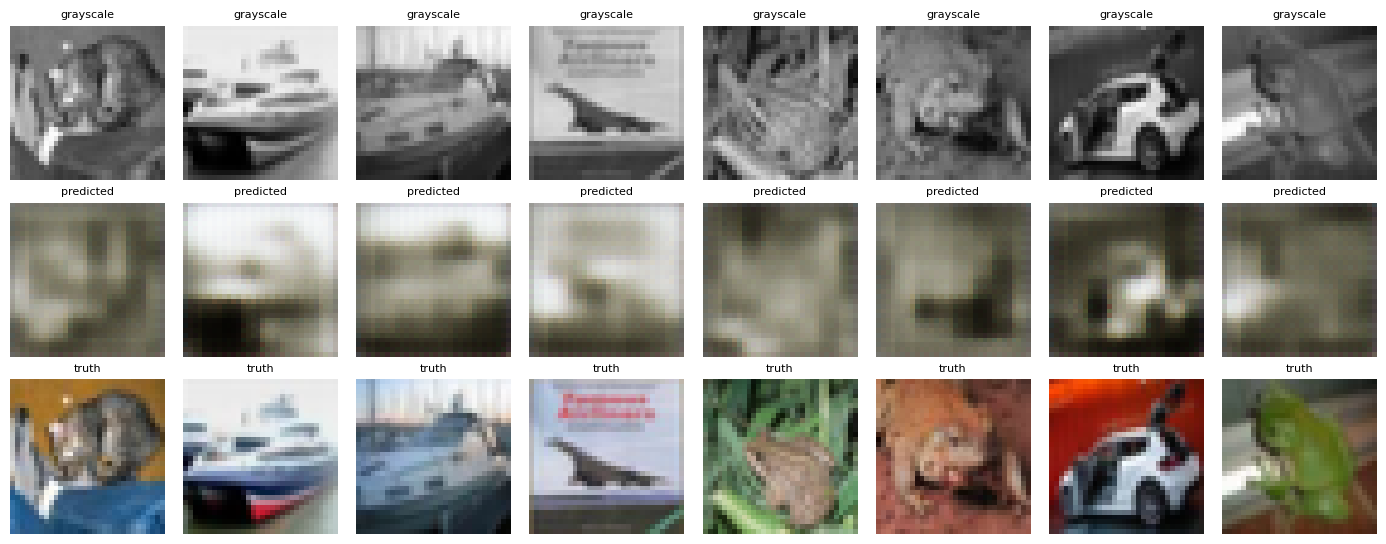

In [5]:
if have_data:
    model.eval()
    xb, _ = next(iter(test_dl))
    xb = xb[:8].to(device)
    gray = to_gray(xb)
    with torch.no_grad():
        pred = model(gray)
    pred01 = ((pred + 1) / 2).clamp(0, 1)
    gray_show = gray.expand(-1, 3, -1, -1)

    fig, axes = plt.subplots(3, 8, figsize=(14, 5.5))
    for j in range(8):
        axes[0, j].imshow(gray_show[j].cpu().permute(1, 2, 0))
        axes[0, j].set_title("grayscale", fontsize=8); axes[0, j].axis("off")
        axes[1, j].imshow(pred01[j].cpu().permute(1, 2, 0))
        axes[1, j].set_title("predicted",  fontsize=8); axes[1, j].axis("off")
        axes[2, j].imshow(xb[j].cpu().permute(1, 2, 0))
        axes[2, j].set_title("truth", fontsize=8); axes[2, j].axis("off")
    plt.tight_layout(); plt.show()
else:
    print("no data to show")

## Honest reading of the samples

What you'll typically see at this scale and budget: the model picks up "sky-ish things are blueish", "grass-ish things are greenish", but skin tones, vehicle paints, and anything that *could* plausibly be many colors comes out desaturated and brownish. That's the well-known mode-averaging failure of L1/L2 colorization — the network hedges toward the per-pixel mean over the conditional distribution of plausible colors.

The published fix is treating colorization as classification over a quantized color palette (Zhang et al., 2016 "Colorful Image Colorization"). That's a notebook on its own — I wanted to keep this one to the autoencoder baseline so the contrast with that approach is meaningful.